<a href="https://colab.research.google.com/github/YanuarRamadhaniKuswoko/PCVK_Sem5/blob/main/Pertemuan6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PRAKTIKUM FILTER

1.Buat fungsi konvolusi menggunakan algoritma yang telah dijelaskan pada Bagian C, tanpa
menggunakan library atau metode konvolusi dari OpenCV.

2.Berikut merupakan langkah-langkah yang dapat dilakukan:

a. Buat notebook baru pada google colab, dan beri nama Week7.ipynb.

b. Akses file yang terdapat pada drive dan import beberapa library yang dibutuhkan

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import math

c.Buatlah fungsi konvolusi.

In [7]:
def convolution2d(image, kernel, padding=0):
    img_h, img_w = image.shape
    ker_h, ker_w = kernel.shape

    # Menambahkan padding pada gambar jika diperlukan
    if padding:
        padded_image = np.pad(
            image,
            pad_width=padding,
            mode='constant'
        )
    else:
        padded_image = image.copy()

    # Menentukan ukuran hasil konvolusi
    result_h = padded_image.shape[0] - ker_h + 1
    result_w = padded_image.shape[1] - ker_w + 1

    result = np.zeros((result_h, result_w))

    # Proses konvolusi
    for row in range(result_h):
        for col in range(result_w):
            area = padded_image[
                row:row + ker_h,
                col:col + ker_w
            ]

            result[row, col] = np.sum(area * kernel)

    return result

d. Load citra yang akan diproses dan ubah menjadi citra keabuan

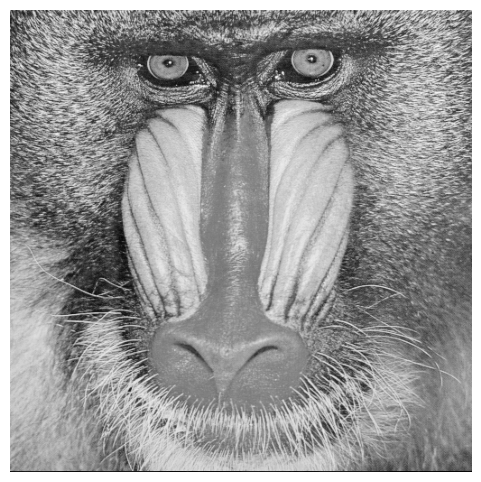

In [8]:
img = cv.imread('/content/drive/MyDrive/PCVK/mandrill.tiff')

img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(6, 6))
plt.imshow(img_gray, cmap='gray')
plt.axis('off')
plt.show()

e. Tentukan kernel yang akan digunakan, contohnya kernel untuk filter sharpening
sebagai berikut:

In [9]:
kernel_sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

print(kernel_sharpen)

[[ 0 -1  0]
 [-1  5 -1]
 [ 0 -1  0]]


f. Memanggil fungsi konvolusi yang telah dibuat sebelumnya, dan menampilkan hasil
konvolusinya:

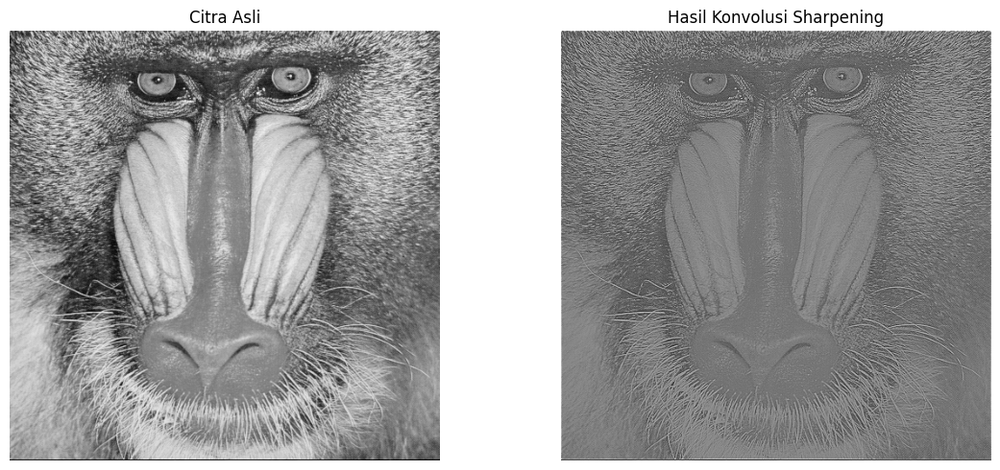

In [10]:
hasil_konvolusi = convolution2d(img_gray, kernel_sharpen, padding=1)

plt.figure(figsize=(12, 5))

# Menampilkan citra awal
plt.subplot(121)
plt.imshow(img_gray, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

# Menampilkan hasil sharpening
plt.subplot(122)
plt.imshow(hasil_konvolusi, cmap='gray')
plt.title('Hasil Konvolusi Sharpening')
plt.axis('off')

plt.tight_layout()
plt.show()

3.Buat Image Filter untuk Average filter, low pass filter, high pass filter, dan beberapa filter
berikut:

In [13]:
def convolution2d(image, kernel, stride=1, padding=0):
    img_h, img_w = image.shape
    kernel_h, kernel_w = kernel.shape

    # Pad image jika padding > 0
    if padding > 0:
        padded_image = np.pad(image, ((padding, padding), (padding, padding)), mode='constant', constant_values=0)
    else:
        padded_image = image.copy()

    out_h = int((padded_image.shape[0] - kernel_h) / stride) + 1
    out_w = int((padded_image.shape[1] - kernel_w) / stride) + 1

    output = np.zeros((out_h, out_w))

    for i in range(0, out_h):
        for j in range(0, out_w):
            start_i = i * stride
            start_j = j * stride
            roi = padded_image[start_i:start_i + kernel_h, start_j:start_j + kernel_w]
            output[i, j] = np.sum(roi * kernel)

    output = np.clip(output, 0, 255)
    return output.astype(np.uint8)

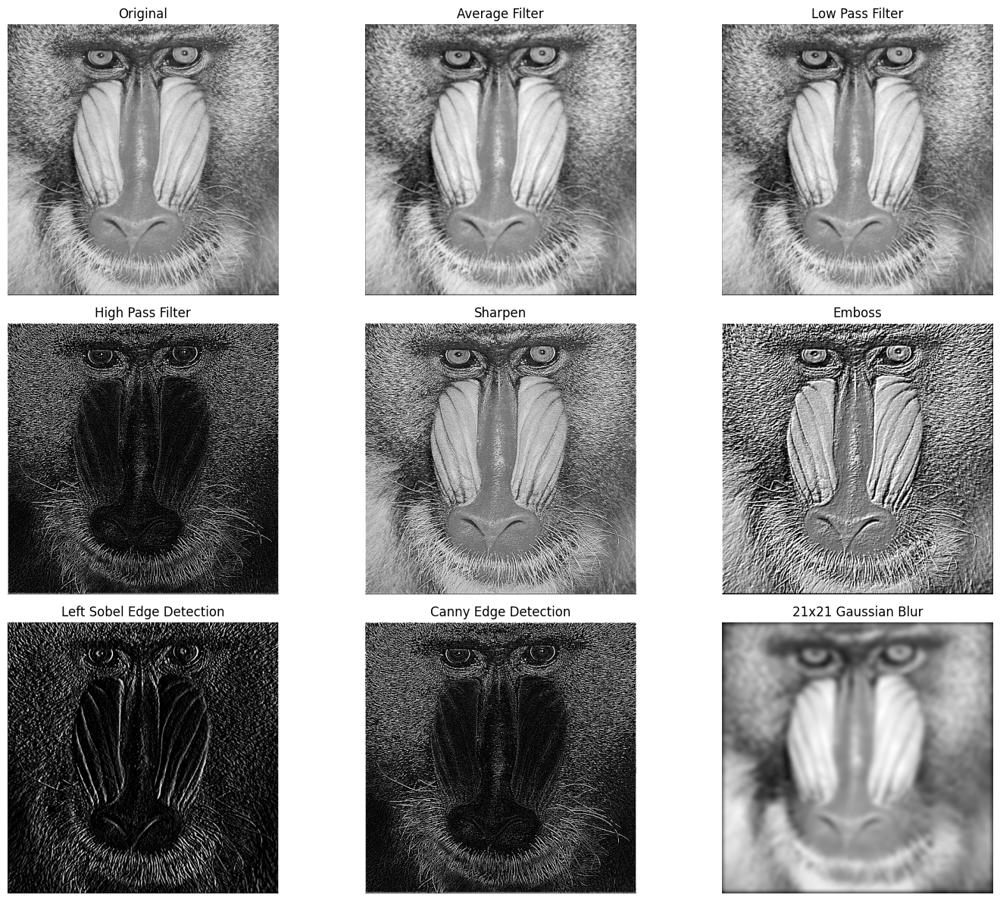

In [14]:
# --- 1. Definisi Kernel Filter ---

# Average Filter ( Mean Filter 3x3 )
kernel_average = np.ones((3, 3), np.float32) / 9.0

# Low Pass Filter ( LPF 3x3 )
kernel_lpf = np.array([
    [1, 1, 1],
    [1, 4, 1],
    [1, 1, 1]
], dtype=np.float32) / 12.0

# High Pass Filter ( HPF 3x3 )
kernel_hpf = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

# Sharpen
kernel_sharpen = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

# Emboss
kernel_emboss = np.array([
    [-2, -1,  0],
    [-1,  1,  1],
    [ 0,  1,  2]
], dtype=np.float32)

# Left Sobel Edge Detection
kernel_left_sobel = np.array([
    [1, 0, -1],
    [2, 0, -2],
    [1, 0, -1]
], dtype=np.float32)

# Canny Edge Detection ( High Pass Laplacian Filter )
kernel_canny = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

# 21x21 Gaussian Blur Kernel Generation
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel_1d = cv.getGaussianKernel(kernel_size, sigma)
kernel_gaussian_21 = gaussian_kernel_1d @ gaussian_kernel_1d.transpose()


# --- 2. Pemanggilan Konvolusi ---

res_average    = convolution2d(img_gray, kernel_average, 1, 1)
res_lpf        = convolution2d(img_gray, kernel_lpf, 1, 1)
res_hpf        = convolution2d(img_gray, kernel_hpf, 1, 1)
res_sharpen    = convolution2d(img_gray, kernel_sharpen, 1, 1)
res_emboss     = convolution2d(img_gray, kernel_emboss, 1, 1)
res_left_sobel = convolution2d(img_gray, kernel_left_sobel, 1, 1)
res_canny      = convolution2d(img_gray, kernel_canny, 1, 1)
res_gaussian   = convolution2d(img_gray, kernel_gaussian_21, 1, 10)

# --- 3. Visualisasi Hasil ---

filters = [
    ("Original", img_gray),
    ("Average Filter", res_average),
    ("Low Pass Filter", res_lpf),
    ("High Pass Filter", res_hpf),
    ("Sharpen", res_sharpen),
    ("Emboss", res_emboss),
    ("Left Sobel Edge Detection", res_left_sobel),
    ("Canny Edge Detection", res_canny),
    ("21x21 Gaussian Blur", res_gaussian)
]

plt.figure(figsize=(15, 12))
for i, (title, img_res) in enumerate(filters):
    plt.subplot(3, 3, i + 1)
    plt.imshow(img_res, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

## FILTER LIBRARY DAN FILTER MODERN

Percobaan 1:

Pada percobaan 1 ini, kita akan membuat Filter Gaussian, Sharpen, dan Canny menggunakan library
filter2d dari OpenCV.

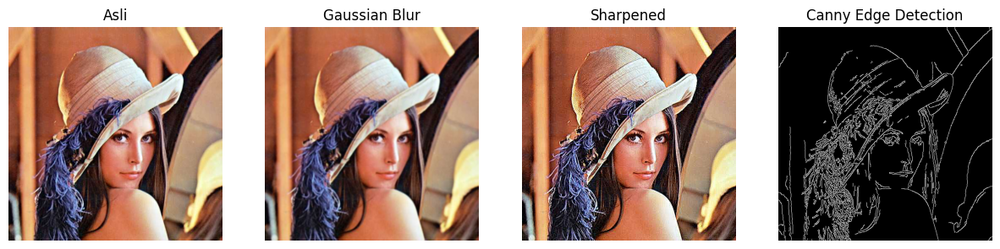

In [18]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# 1. Definisi fungsi untuk menampilkan gambar secara berdampingan
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:  # grayscale
            plt.subplot(1, len(images), i + 1)
            plt.imshow(img, cmap="gray")
        else:  # color (BGR to RGB)
            plt.subplot(1, len(images), i + 1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

# 2. Load gambar (sesuaikan path gambar di Google Drive kamu)
img_path = "/content/drive/MyDrive/PCVK/lena.jpg"
img = cv.imread(img_path)

# Pastikan gambar berhasil dimuat sebelum menjalankan operasi filter
if img is None:
    print("Gambar tidak ditemukan. Cek kembali path lokasi file lena.jpg Anda.")
else:
    # Ubah gambar ke grayscale untuk keperluan deteksi tepi Canny
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # 3. Penerapan filter
    # Gaussian Blur (pada citra RGB)
    blur = cv.GaussianBlur(img, (7, 7), 1)

    # Canny Edge Detection (pada citra Grayscale)
    edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)

    # Sharpening menggunakan cv.filter2D (pada citra RGB)
    sharpen_kernel = np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ])
    sharpened = cv.filter2D(img, -1, sharpen_kernel)

    # 4. Tampilkan hasil secara berdampingan
    show_side_by_side(
        [img, blur, sharpened, edges],
        ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"]
    )

Percobaan 2:

Pada percobaan 2 berikut ini akan dilakukan filtering modern dari Library OpenCV. Dua filter yang akan
digunakan adalah Bilateral Filtering dan Guided Filter.

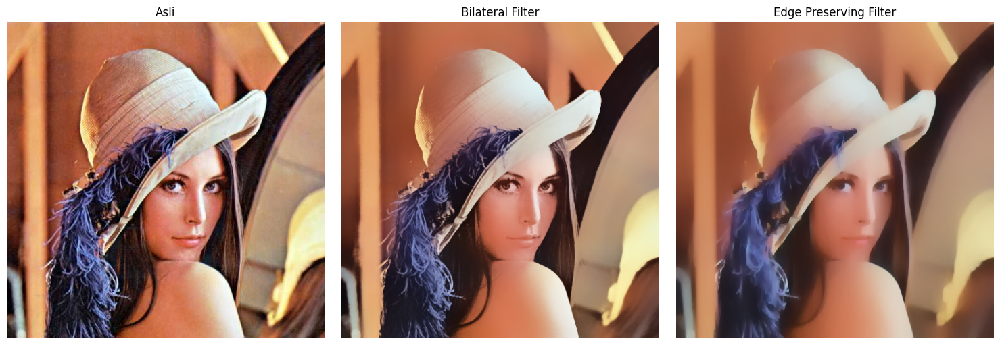

In [19]:
lokasi_file = "/content/drive/MyDrive/PCVK/lena.jpg"

gambar = cv.imread(lokasi_file)

# Bilateral Filter
hasil_bilateral = cv.bilateralFilter(
    gambar,
    50,
    100,
    100
)

# Edge Preserving Filter
hasil_edge_preserve = cv.edgePreservingFilter(
    gambar,
    flags=1,
    sigma_s=100,
    sigma_r=0.9
)

# Menampilkan hasil
tampilkan_gambar(
    [gambar, hasil_bilateral, hasil_edge_preserve],
    [
        "Asli",
        "Bilateral Filter",
        "Edge Preserving Filter"
    ]
)

Percobaan 3:

Percobaan kali ini akan mencoba melihat proses Filtering pada CNN (bagian Feature Map)

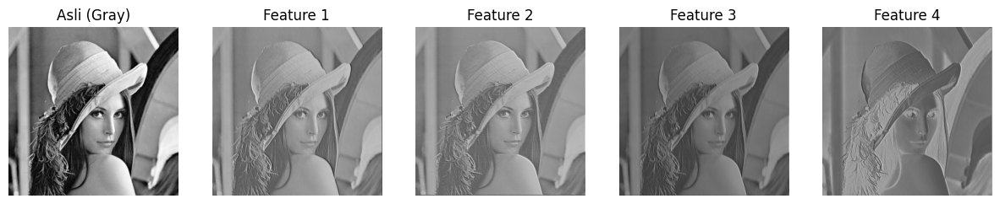

In [20]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# 1. Definisikan Arsitektur CNN Sederhana
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # 1 channel input (grayscale), 4 channel output (feature maps)
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

# 2. Inisialisasi Model
model = SimpleCNN()

# 3. Ubah Gambar ke Tensor PyTorch
# Menambahkan dimensi batch dan channel: (B, C, H, W) -> (1, 1, H, W)
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# 4. Extract Feature Maps tanpa Menghitung Gradien
with torch.no_grad():
    features = model(img_tensor)

# 5. Visualisasi Feature Maps
feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps, ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])

Percobaan 4:

Percobaan kali ini akan melakukan efek Beauty dan Vintage yang biasanya digunakan pada Aplikasi
popular saat ini.

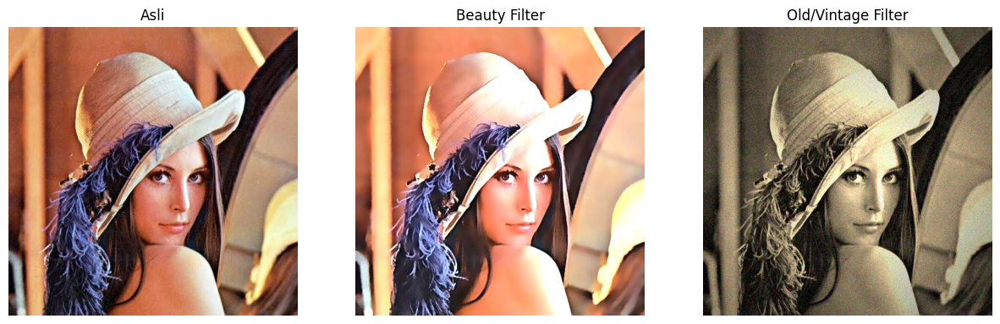

In [21]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# ===============================
# 1. Beauty Filter
# ===============================

# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# Step 2: Unsharp masking (pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0, 0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# Step 3: Brightness & contrast
alpha = 1.2  # contrast
beta = 15    # brightness
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)


# ===============================
# 2. Old/Vintage Filter
# ===============================

# Step 1: Sepia tone
sepia_kernel = np.array([
    [0.272, 0.534, 0.131],
    [0.349, 0.686, 0.168],
    [0.393, 0.769, 0.189]
])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols * 0.6)
kernel_y = cv.getGaussianKernel(rows, rows * 0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:, :, i] = vignette[:, :, i] * mask

# Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)


# ===============================
# 3. Visualisasi Hasil
# ===============================

show_side_by_side(
    [img, beauty, old_img],
    ["Asli", "Beauty Filter", "Old/Vintage Filter"]
)

Percobaan 5:

Percobaan 5 akan menunjukkan pada anda filter anime / cartoon menggunakan kombinasi filter
tradisional.

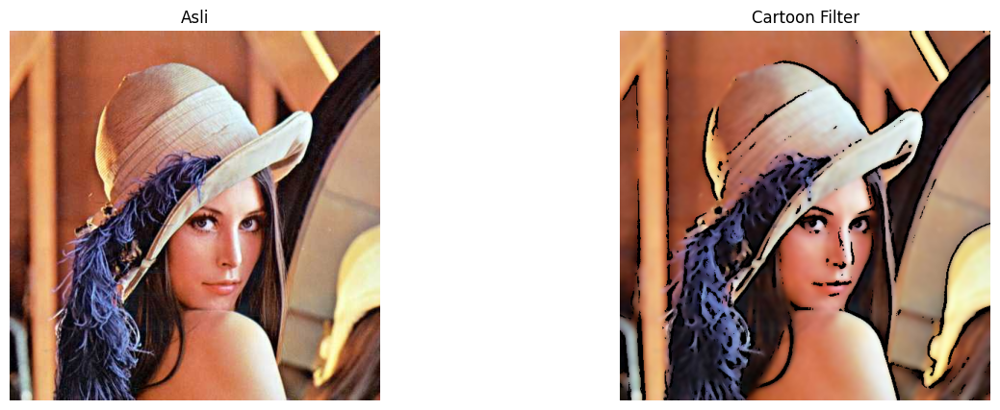

In [22]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# ===============================
# Filter Anime / Cartoon
# ===============================

# Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(
    gray_blur,
    255,
    cv.ADAPTIVE_THRESH_MEAN_C,
    cv.THRESH_BINARY,
    9,
    9
)

# Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)

# Tampilkan hasil secara berdampingan
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

Percobaan 6:

Pada Percobaan 6 akan ditunjukkan contoh Filter Malam.

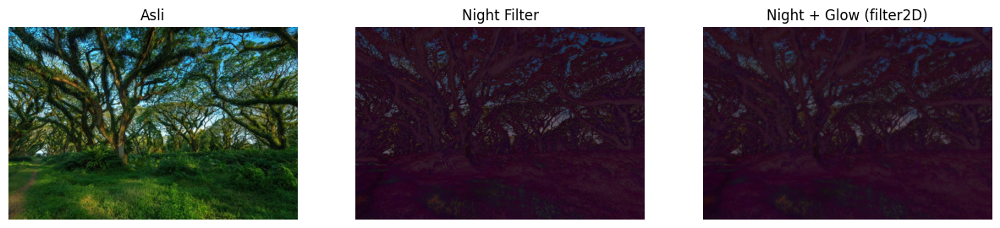

In [23]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# ===============================
# Night Filter
# ===============================

# Read image (sesuaikan path di Google Drive kamu)
img_night_path = "/content/drive/MyDrive/PCVK/djawatan.jpg"
img = cv.imread(img_night_path)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Step 1: Gelapkan (contrast turun, brightness negatif)
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

# Step 2: Tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100))  # BGR: B=50, G=0, R=100
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# Step 3: Efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15, 15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

# Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

# Tampilkan hasil secara berdampingan
show_side_by_side(
    [img, night, night_glow],
    ["Asli", "Night Filter", "Night + Glow (filter2D)"]
)

Percobaan 7:

Percobaan 7 menunjukkan Filter Pagi dan Pagi ditambahkan efek kabut.

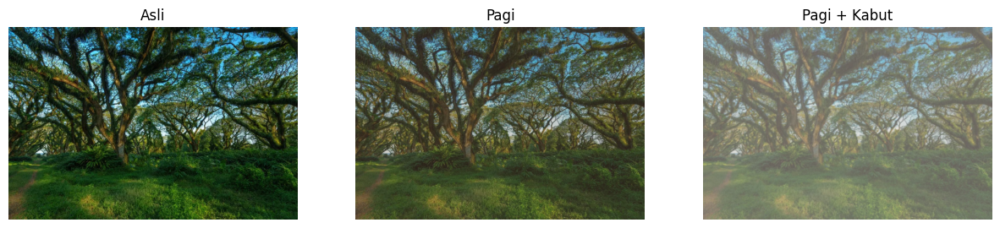

In [24]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# ===============================
# Filter Suasana Pagi dan Kabut
# ===============================

# Step 1: Kurangi kontras & cerahkan
alpha = 0.9  # contrast
beta = 20    # brightness
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# Step 2: Tambahkan warm tone (kemerahan / oranye)
warm_tint = np.full_like(soft, (40, 70, 120))  # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# Step 3: Tambahkan haze (kabut tipis) dengan filter2D
# Kernel blur Gaussian-like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T  # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# Tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

# Tampilkan hasil secara berdampingan
show_side_by_side(
    [img, pagi, kabut],
    ["Asli", "Pagi", "Pagi + Kabut"]
)

## Tugas Praktikum
1.Tugas Analisis: Perbandingan Mean Filter (Blur Biasa) vs. Median Filter pada Noise “Salt and
Pepper”

a. Tambahkan noise bintik hitam-putih (Salt and Pepper) ke sebuah citra keabuan (grayscale).

b. Terapkan Mean Filter(3 x 3) dan Median Filter (3 x 3).

c. Amati dan analisis secara visual mengapa Median Filter jauh lebih bersih dalam menghapus
noise tersebut dibanding Mean Filter.

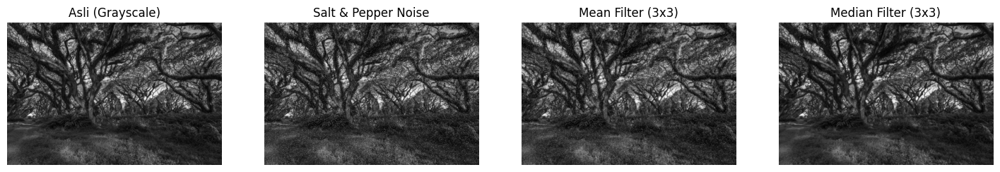

In [25]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# 1. Fungsi untuk menambahkan Salt and Pepper Noise
def add_salt_and_pepper_noise(image, amount=0.04):
    noisy_image = image.copy()
    num_salt = np.ceil(amount * image.size * 0.5)
    num_pepper = np.ceil(amount * image.size * 0.5)

    # Salt noise (piksel putih = 255)
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
    noisy_image[tuple(coords)] = 255

    # Pepper noise (piksel hitam = 0)
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
    noisy_image[tuple(coords)] = 0

    return noisy_image

# 2. Tambahkan noise ke citra grayscale
img_noisy = add_salt_and_pepper_noise(img_gray, amount=0.05)

# 3. Terapkan Mean Filter 3x3 dan Median Filter 3x3
# Mean Filter (Average Filter)
kernel_mean = np.ones((3, 3), np.float32) / 9.0
img_mean_filtered = cv.filter2D(img_noisy, -1, kernel_mean)

# Median Filter
img_median_filtered = cv.medianBlur(img_noisy, 3)

# 4. Tampilkan hasil secara berdampingan
show_side_by_side(
    [img_gray, img_noisy, img_mean_filtered, img_median_filtered],
    ["Asli (Grayscale)", "Salt & Pepper Noise", "Mean Filter (3x3)", "Median Filter (3x3)"],
    figsize=(18, 5)
)

-Mean Filter: Nilai noise yang ekstrem (hitam banget 0 atau putih banget 255) ikut dijumlahkan dan dibagi. Hasilnya, nilai piksel di sekitarnya ikut ketularan rusak, bikin gambar jadi buram dan bintiknya cuma "pudar" tapi nggak hilang.
  
-Median Filter: Semua nilai piksel diurutkan dari yang terkecil sampai terbesar, lalu diambil tepat nilai tengahnya. Karena noise ada di angka ujung (0 atau 255), nilainya pasti tercoret dan diganti sama warna piksel tetangganya yang normal. Makanya gambarnya langsung bersih total tanpa merusak tepi objek.

2.Tugas Evaluasi: Pemilihan Ukuran Kernel terbaik untuk Menajamkan Citra (Sharpening)

a. Buat kernel penajaman (Sharpening Kernel) ukuran 3 x 3 dan 5 x 5.

b. Terapkan pada citra yang sedikit buram (blurry).

c. Evaluasi hasilnya berdasarkan aspek Kejelasan Tepi vs. Kadar Noise/Noise Distortion yang
dihasilkan. Tentukan kernel mana yang paling optimal untuk digunakan sehari-hari.

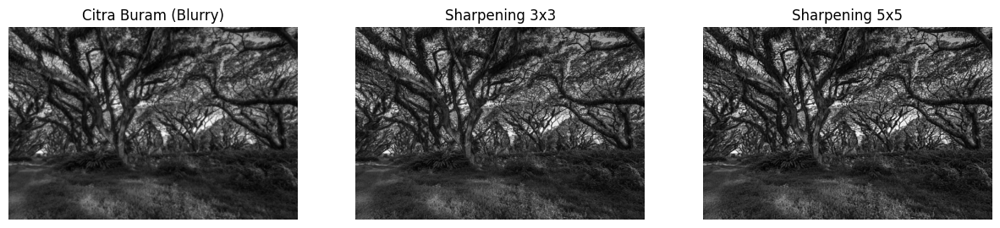

In [26]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# 1. Buat citra sedikit buram (blurry) sebagai bahan pengujian
img_blurry = cv.GaussianBlur(img_gray, (5, 5), 0)

# 2. Definisikan Sharpening Kernel 3x3 dan 5x5
# Kernel Sharpening 3x3
kernel_sharpen_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

# Kernel Sharpening 5x5
kernel_sharpen_5x5 = np.array([
    [-1, -1, -1, -1, -1],
    [-1,  2,  2,  2, -1],
    [-1,  2,  8,  2, -1],
    [-1,  2,  2,  2, -1],
    [-1, -1, -1, -1, -1]
], dtype=np.float32) / 8.0

# 3. Terapkan konvolusi menggunakan cv.filter2D
res_sharpen_3x3 = cv.filter2D(img_blurry, -1, kernel_sharpen_3x3)
res_sharpen_5x5 = cv.filter2D(img_blurry, -1, kernel_sharpen_5x5)

# 4. Tampilkan hasil secara berdampingan
show_side_by_side(
    [img_blurry, res_sharpen_3x3, res_sharpen_5x5],
    ["Citra Buram (Blurry)", "Sharpening 3x3", "Sharpening 5x5"],
    figsize=(15, 5)
)

Hasil Evaluasi & Analisis1.

-Kejelasan Tepi vs. Kadar Noise/Distorsi

a.Kernel 3x3:Menajamkan garis tepi objek secara natural. Detail halus yang kabur kembali terlihat jelas tanpa membuat gambar pecah atau memunculkan bintik-bintik kontras yang berlebihan.   

b.Kernel 5x5: Karena cakupan area pikselnya lebih luas, filter ini meningkatkan kontras tepi secara agresif. Efek sampingnya, tepi objek terlihat terlalu tajam hingga memunculkan efek halo/artefak (garis putih mencolok di pinggir garis) dan membesarkan bintik noise halus menjadi sangat kelihatan.   

Kesimpulan Kernel Optimal untuk Penggunaan Sehari-hari

a.Kernel 3x3 adalah pilihan paling optimal.
b.Kernel 3x3 memberikan keseimbangan terbaik antara penajaman detail objek dan kontrol kadar noise, serta memiliki beban komputasi yang jauh lebih ringan dibanding kernel 5x5

3.Tugas Kreasi: Filter Kartun Sederhana

a. Buatlah sebuah fungsi kustom bernama kartun(image) yang menggabungkan:
* Penghalusan warna menggunakan **Bilateral Filter** agar area warna menjadi rata.
* Deteksi garis tepi menggunakan **Adaptive Thresholding** atau **Canny Edge**.
* Penggabungan (kombinasi) keduanya menggunakan operasi logika/perkalian piksel.

b. Tampilkan hasil citra asli dengan citra efek kartun bersebelahan.

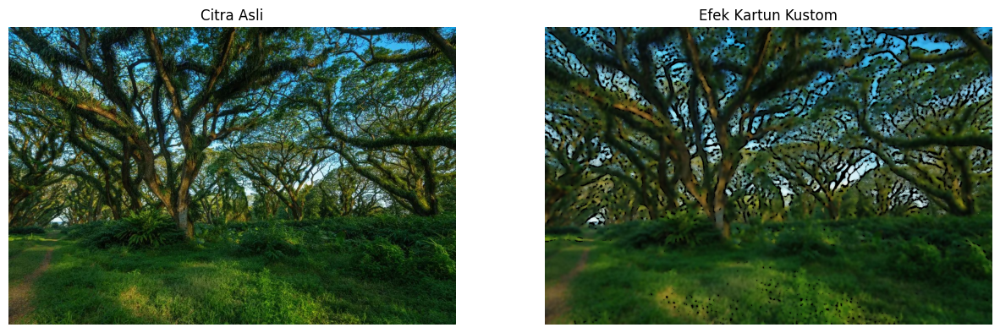

In [27]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# a. Buat fungsi kustom bernama kartun(image)
def kartun(image):
    # 1. Edge detection (menggunakan Canny atau Adaptive Thresholding)
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray, 7)

    # Menggunakan Adaptive Thresholding untuk garis tepi khas kartun
    edges = cv.adaptiveThreshold(
        gray_blur,
        255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        9,
        9
    )

    # 2. Penghalusan warna menggunakan Bilateral Filter
    color = cv.bilateralFilter(image, d=9, sigmaColor=200, sigmaSpace=200)

    # 3. Penggabungan menggunakan operasi logika bitwise AND
    cartoon_img = cv.bitwise_and(color, color, mask=edges)

    return cartoon_img

# Menjalankan fungsi kustom pada citra
hasil_kartun = kartun(img)

# b. Tampilkan hasil citra asli dengan citra efek kartun bersebelahan
show_side_by_side([img, hasil_kartun], ["Citra Asli", "Efek Kartun Kustom"])

Penjelasan Singkat Fungsi:

-Bilateral Filter menghaluskan gradasi warna pada area wajah atau latar belakang tanpa merusak ketajaman batas warna.   

-Adaptive Thresholding membuat sketsa garis tepi (outline) berwarna hitam tebal yang memberikan kesan gambar komik.   

-Bitwise AND menempelkan garis tepi hitam tersebut di atas citra yang warna Permukaannya sudah diratakan.   